In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
from tqdm import tqdm

In [2]:
mean = np.load("/data/base/test_climato_ft_2/mean.npy")
std = np.load("/data/base/test_climato_ft_2/std.npy")

In [3]:
std

array([0.49782494], dtype=float32)

In [48]:
# Define number of files
num_files = 727
min=1000
max=-1000

# Iterate over all files and update histogram progressively
for i in tqdm(range(0,num_files+1,44)):
    file_path = f"/data/base/test_climato_ft/preds_{i}.npy"
    if os.path.exists(file_path):
        data = np.load(file_path, allow_pickle=True).reshape(-1)*std + mean  # Flatten
        # Update min and max
        min = np.min([min, np.min(data)])
        max = np.max([max, np.max(data)])
    else:
        print(f"Warning: {file_path} not found.")

100%|██████████| 17/17 [00:00<00:00, 25.29it/s]


In [49]:
min, max

(-8.29374885559082, 22.925806045532227)

100%|██████████| 17/17 [00:16<00:00,  1.06it/s]


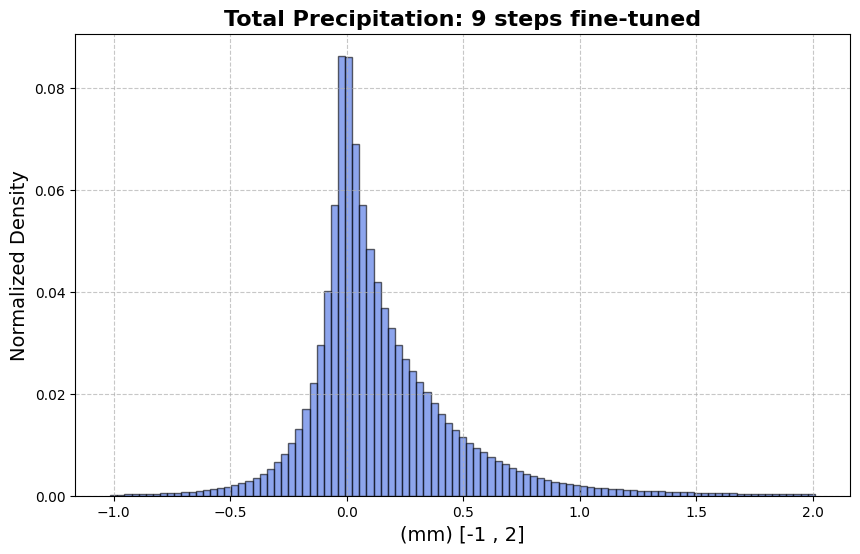

In [19]:
# Define number of files
num_files = 727

# Histogram parameters
bins = 100
hist_bins = np.linspace(-1, 2.025, bins)  # Adjust range as needed
hist_counts = np.zeros(bins - 1)  # To accumulate counts

# Iterate over all files and update histogram progressively
for i in tqdm(range(0,num_files+1,44)):
    file_path = f"/data/base/test_climato_ft/preds_{i}.npy"
    if os.path.exists(file_path):
        data = np.load(file_path, allow_pickle=True).reshape(-1)*std + mean  # Flatten
        #print(np.min(data), np.max(data))
        hist_counts += np.histogram(data, bins=hist_bins)[0]  # Accumulate counts
    else:
        print(f"Warning: {file_path} not found.")

# Normalize histogram
hist_counts = hist_counts / np.sum(hist_counts)

# Plot optimized histogram
plt.figure(figsize=(10, 6))
plt.bar(hist_bins[:-1], hist_counts, width=np.diff(hist_bins), color='royalblue', alpha=0.6, edgecolor='black', label="Histogram")

plt.xlabel("(mm) [-1 , 2]", fontsize=14)
plt.ylabel("Normalized Density", fontsize=14)
plt.title("Total Precipitation: 9 steps fine-tuned", fontsize=16, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.7)

plt.show()

100%|██████████| 17/17 [00:16<00:00,  1.02it/s]


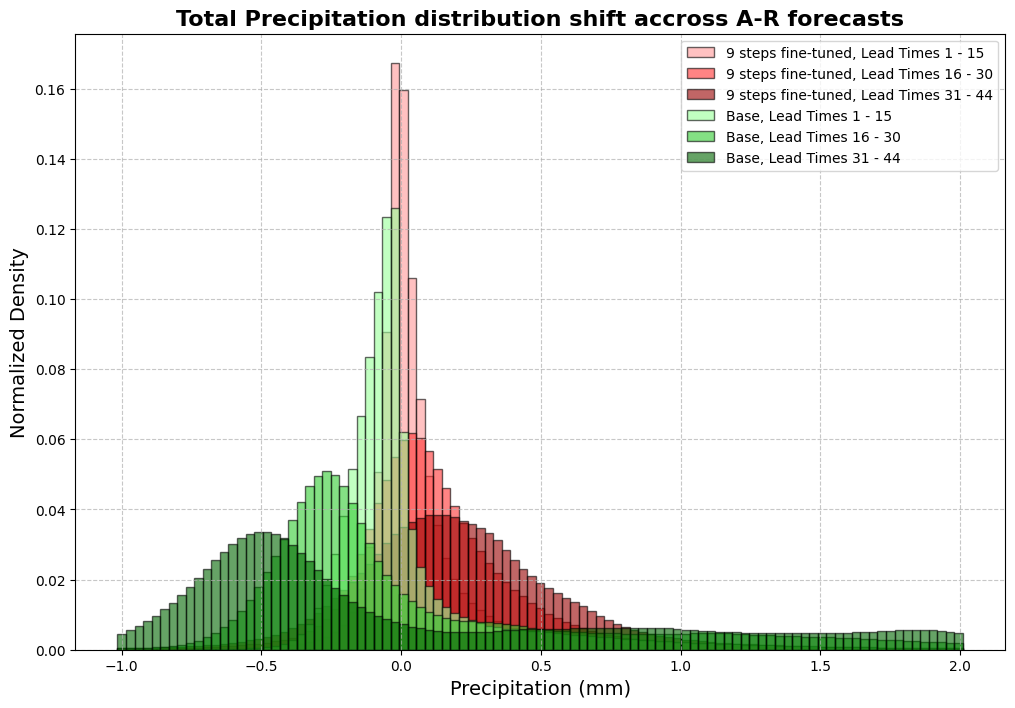

In [20]:
import numpy as np
import os
import matplotlib.pyplot as plt
from tqdm import tqdm

# Define number of files
num_files = 727

# Histogram parameters
bins = 100
hist_bins = np.linspace(-1, 2.025, bins)  # Adjust range as needed

# Initialize histograms for each lead time group
num_groups = 3  # Now we have three groups: (1-15, 16-30, 31-44)
hist_counts_list = [np.zeros(bins - 1) for _ in range(num_groups)]

# Iterate over all files and update histograms for each lead time group
for i in tqdm(range(0, num_files + 1, 44)):
    file_path = f"/data/base/test_climato_ft/preds_{i}.npy"
    
    if os.path.exists(file_path):
        data = np.load(file_path, allow_pickle=True).reshape(1, 44, 512, 640) * std + mean  # Shape (1,44,512,640)
        
        for group_idx in range(num_groups):
            start_lt = group_idx * 15
            end_lt = min(start_lt + 15, 44)  # Ensuring the last group covers remaining lead times
            
            group_data = data[:, start_lt:end_lt, :, :].flatten()  # Flatten selected lead times
            hist_counts_list[group_idx] += np.histogram(group_data, bins=hist_bins)[0]  # Accumulate counts
    
    else:
        print(f"Warning: {file_path} not found.")

# Normalize histograms
hist_counts_list = [counts / np.sum(counts) for counts in hist_counts_list]

# Define shades of red for the histograms
red_shades = ["#ff9999", "#ff3333", "#990000"]  # Light, Medium, Dark Red

# Plot histograms for each lead time group
plt.figure(figsize=(12, 8))
for group_idx in range(num_groups):
    plt.bar(hist_bins[:-1], hist_counts_list[group_idx], width=np.diff(hist_bins),
            alpha=0.6, edgecolor='black', label=f"9 steps fine-tuned, Lead Times {group_idx*15+1} - {min((group_idx+1)*15, 44)}", color=red_shades[group_idx])
    


# Initialize histograms for each lead time group
num_groups = 3  # Now we have three groups: (1-15, 16-30, 31-44)
hist_counts_list = [np.zeros(bins - 1) for _ in range(num_groups)]

# Iterate over all files and update histograms for each lead time group
for i in tqdm(range(0, num_files + 1, 44)):
    file_path = f"/data/base/test_climato/preds_{i}.npy"
    
    if os.path.exists(file_path):
        data = np.load(file_path, allow_pickle=True).reshape(1, 44, 512, 640) * std + mean  # Shape (1,44,512,640)
        
        for group_idx in range(num_groups):
            start_lt = group_idx * 15
            end_lt = min(start_lt + 15, 44)  # Ensuring the last group covers remaining lead times
            
            group_data = data[:, start_lt:end_lt, :, :].flatten()  # Flatten selected lead times
            hist_counts_list[group_idx] += np.histogram(group_data, bins=hist_bins)[0]  # Accumulate counts
    
    else:
        print(f"Warning: {file_path} not found.")

# Normalize histograms
hist_counts_list = [counts / np.sum(counts) for counts in hist_counts_list]

# Define shades of red for the histograms
green_shades = ["#99ff99", "#33cc33", "#006600"]  # Light, Medium, Dark green

# Plot histograms for each lead time group
for group_idx in range(num_groups):
    plt.bar(hist_bins[:-1], hist_counts_list[group_idx], width=np.diff(hist_bins),
            alpha=0.6, edgecolor='black', label=f"Base, Lead Times {group_idx*15+1} - {min((group_idx+1)*15, 44)}", color=green_shades[group_idx])

plt.xlabel("Precipitation (mm)", fontsize=14)
plt.ylabel("Normalized Density", fontsize=14)
plt.title("Total Precipitation distribution shift accross A-R forecasts", fontsize=16, fontweight="bold")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)

plt.show()


100%|██████████| 17/17 [00:07<00:00,  2.17it/s]


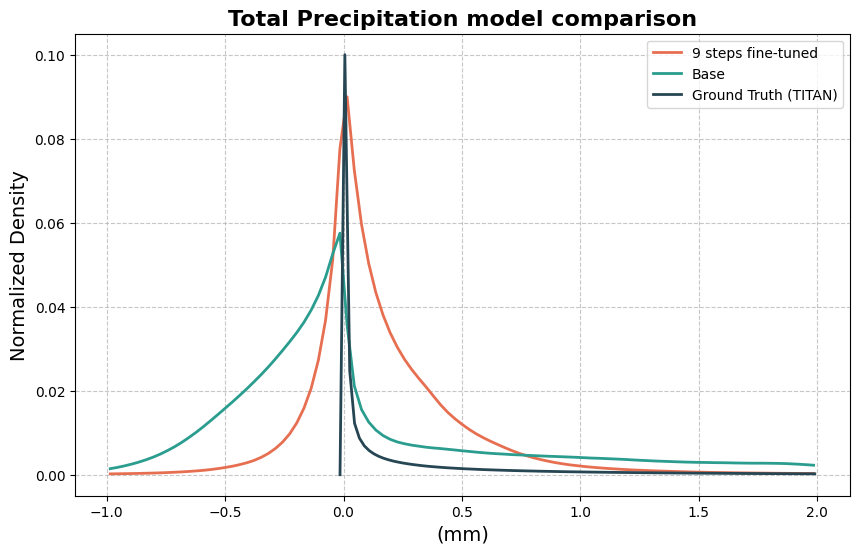

In [13]:
# Define number of files
num_files = 727

# Histogram parameters
bins = 100
hist_bins = np.linspace(-1, 2, bins)  # Adjust range as needed
hist_counts = np.zeros(bins - 1)  # To accumulate counts

# Iterate over all files and update histogram progressively
for i in tqdm(range(0, num_files + 1, 44)):
    file_path = f"/data/base/test_climato_ft/preds_{i}.npy"
    if os.path.exists(file_path):
        data = np.load(file_path, allow_pickle=True).reshape(-1) * std + mean  # Flatten
        hist_counts += np.histogram(data, bins=hist_bins)[0]  # Accumulate counts
    else:
        print(f"Warning: {file_path} not found.")

# Normalize histogram
hist_counts = hist_counts / np.sum(hist_counts)

# Clip y-values to be below 0.1
hist_counts = np.clip(hist_counts, None, 0.1)

# Compute bin centers for smooth line plotting
bin_centers = (hist_bins[:-1] + hist_bins[1:]) / 2

# Plot the smoothed histogram as a line
plt.figure(figsize=(10, 6))
plt.plot(bin_centers, hist_counts, color='#e76f51', linewidth=2, label="9 steps fine-tuned")

# Histogram parameters
bins = 100
hist_bins = np.linspace(-1, 2, bins)  # Adjust range as needed
hist_counts = np.zeros(bins - 1)  # To accumulate counts

# Iterate over all files and update histogram progressively
for i in tqdm(range(0, num_files + 1, 44)):
    file_path = f"/data/base/test_climato/preds_{i}.npy"
    if os.path.exists(file_path):
        data = np.load(file_path, allow_pickle=True).reshape(-1) * std + mean  # Flatten
        hist_counts += np.histogram(data, bins=hist_bins)[0]  # Accumulate counts
    else:
        print(f"Warning: {file_path} not found.")

# Normalize histogram
hist_counts = hist_counts / np.sum(hist_counts)

# Clip y-values to be below 0.1
hist_counts = np.clip(hist_counts, None, 0.1)

# Compute bin centers for smooth line plotting
bin_centers = (hist_bins[:-1] + hist_bins[1:]) / 2

# Plot the smoothed histogram as a line
plt.plot(bin_centers, hist_counts, color='#2a9d8f', linewidth=2, label="Base")

# Histogram parameters
bins = 100
hist_bins = np.linspace(-0.025, 2, bins)  # Adjust range as needed
hist_counts = np.zeros(bins - 1)  # To accumulate counts

# Iterate over all files and update histogram progressively
for i in tqdm(range(0, num_files + 1, 44)):
    file_path = f"/data/base/test_climato/targets_{i}.npy"
    if os.path.exists(file_path):
        data = np.load(file_path, allow_pickle=True).reshape(-1) * std + mean  # Flatten
        hist_counts += np.histogram(data, bins=hist_bins)[0]  # Accumulate counts
    else:
        print(f"Warning: {file_path} not found.")

# Normalize histogram
hist_counts = hist_counts / np.sum(hist_counts)

# Clip y-values to be below 0.1
hist_counts = np.clip(hist_counts, None, 0.1)

# Compute bin centers for smooth line plotting
bin_centers = (hist_bins[:-1] + hist_bins[1:]) / 2

# Plot the smoothed histogram as a line
plt.plot(bin_centers, hist_counts, color='#264653', linewidth=2, label="Ground Truth (TITAN)")



plt.xlabel("(mm)", fontsize=14)
plt.ylabel("Normalized Density", fontsize=14)
plt.title("Total Precipitation model comparison", fontsize=16, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend()

plt.show()


100%|██████████| 17/17 [00:16<00:00,  1.06it/s]


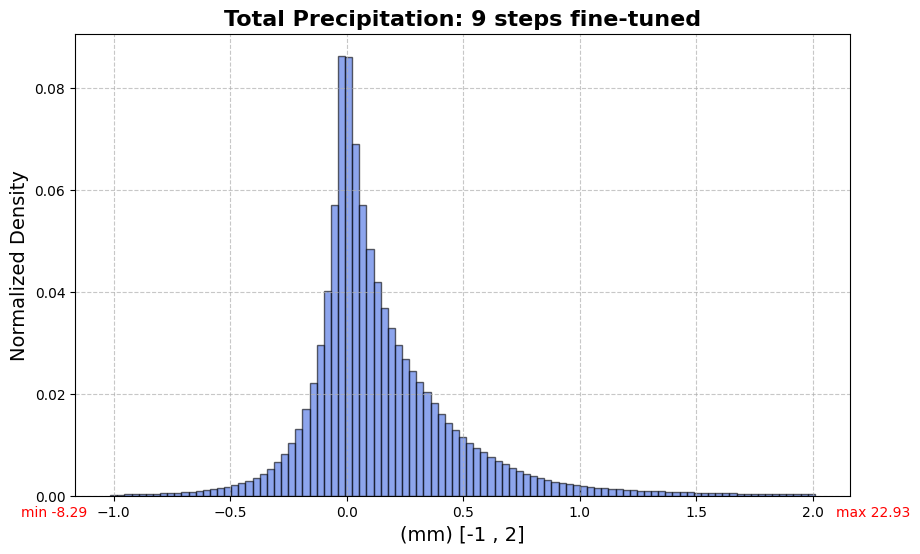

In [51]:
# Define number of files
num_files = 727

# Histogram parameters
bins = 100
hist_bins = np.linspace(-1, 2.025, bins)  # Adjust range as needed
hist_counts = np.zeros(bins - 1)  # To accumulate counts

# Iterate over all files and update histogram progressively
for i in tqdm(range(0,num_files+1,44)):
    file_path = f"/data/base/test_climato_ft/preds_{i}.npy"
    if os.path.exists(file_path):
        data = np.load(file_path, allow_pickle=True).reshape(-1)*std + mean  # Flatten
        #print(np.min(data), np.max(data))
        hist_counts += np.histogram(data, bins=hist_bins)[0]  # Accumulate counts
    else:
        print(f"Warning: {file_path} not found.")

# Normalize histogram
hist_counts = hist_counts / np.sum(hist_counts)

# Plot optimized histogram
plt.figure(figsize=(10, 6))
plt.bar(hist_bins[:-1], hist_counts, width=np.diff(hist_bins), color='royalblue', alpha=0.6, edgecolor='black', label="Histogram")

plt.xlabel("(mm) [-1 , 2]", fontsize=14)
plt.ylabel("Normalized Density", fontsize=14)
plt.text(2.1, -0.004, 'max 22.93', fontsize=10, color='red')
plt.text(-1.4, -0.004, 'min -8.29', fontsize=10, color='red')
plt.title("Total Precipitation: 9 steps fine-tuned", fontsize=16, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.7)

plt.show()